In [5]:
# input variables: file_path as a .csv, run_num as a run
# params

In [6]:
import math
from math import*
import numpy as np
import pandas as pd

In [7]:
def delta_p_df(df):
    return df.diff(axis=1).iloc[:, 1:]

In [23]:
def transpose_file(file_path):
    with open(f"{file_path}", 'r') as f:
        max_cols = max(len(line.split(',')) for line in f)

    col_names = [f"col_{i}" for i in range(max_cols)]
    
    df = pd.read_csv(
        file_path, 
        names=col_names, 
        header=None,  
        engine='python'
    )
    dft = df.T

    dft.columns = dft.iloc[0]

    dft = dft.iloc[1:].reset_index(drop=True)

    return dft

In [9]:
from itertools import product

def between_sites(site1, site2, gens1, gens2, reps1, reps2, site1_id, site2_id):

    gens = sorted(list(set(gens1) & set(gens2)))
    
    reps_1 = [str(r) for r in reps1]
    reps_2 = [str(r) for r in reps2]

    correlations_through_time = {}
    for g in gens:
        str_g = str(g)
        cols_site1 = [col for col in site1.columns if col.split("_")[1] == str_g]
        cols_site2 = [col for col in site2.columns if col.split("_")[1] == str_g]

        site1_time_g = site1[cols_site1]
        site2_time_g = site2[cols_site2]

        cov_sites_time_g = pd.concat([site1_time_g, site2_time_g], axis = 1).dropna().cov()

        columns_map = {}
        for col in cov_sites_time_g.columns:
            parts = col.split("_")
            if len(parts)>=3:
                columns_map[(str(parts[0]), str(parts[2]))] = col
        
        rep_pairs = list(product(reps_1, reps_2))

        s1, s2 = str(site1_id), str(site2_id)
        
        correlations = []
        for rep1, rep2 in rep_pairs:
            cols_s1_rep1 = columns_map.get((s1, rep1))
            cols_s2_rep2 = columns_map.get((s2, rep2))

            if not (cols_s1_rep1 and cols_s2_rep2):
                continue 

            cov = np.nanmean(cov_sites_time_g.loc[cols_s1_rep1, cols_s2_rep2])
            var_s1_rep1 = cov_sites_time_g.loc[cols_s1_rep1, cols_s1_rep1]
            var_s2_rep2 = cov_sites_time_g.loc[cols_s2_rep2, cols_s2_rep2]

            denom = np.nanmean(np.sqrt(var_s1_rep1*var_s2_rep2))
            if denom>0:
                corr = cov/denom

                correlations.append(corr)

        val = corr if corr else np.nan
        
        correlations_through_time[g] = val

    return pd.Series(correlations_through_time)

In [10]:
def delta_p_all_reps_sim(df):
    rep_list = list(dict.fromkeys(sorted((col.split('_')[2]) for col in df.columns)))[1:]
    delta_p_list = []
    for r in rep_list:
        rep_df = df.filter(regex=f"{r}|p0")
        delta_p = delta_p_df(rep_df)
        delta_p_list.append(delta_p)

    combined_delta_p = pd.concat(delta_p_list, axis=1)

    return combined_delta_p

In [24]:
import pathlib
file_paths = snakemake.input
simulated_convergences = pathlib.Path(f"simulated_conv_corr_snakeflow.csv")

for file in file_paths:
    sim_num = file.split("_")[3].replace(".csv", "")

    sim_df = transpose_file(file)

    sub_15000 = sim_df.filter(like="15000").copy().reset_index(drop=True)
    sub_15001 = sim_df.filter(like="15001").copy().reset_index(drop=True)
    sub_15002 = sim_df.filter(like="15002").copy().reset_index(drop=True)
    sub_15003 = sim_df.filter(like="15003").copy().reset_index(drop=True)
    
    matches_1 = pd.merge(sub_15000, sub_15001, how='left', left_on= sub_15000.columns[0], right_on=sub_15001.columns[0]).dropna()
    matches_2 = pd.merge(matches_1, sub_15002, how='left', left_on= matches_1.columns[0], right_on=sub_15002.columns[0]).dropna()
    matches = pd.merge(matches_2, sub_15003, how='left', left_on= matches_2.columns[0], right_on=sub_15003.columns[0]).dropna()
    matches = matches.loc[:, ~matches.columns.str.contains("pos")].copy().reset_index(drop=True)
    matches = matches.replace(0, np.nan).replace(1, np.nan)
    
    site_X = matches.filter(regex="p0|Xs")
    site_Y = matches.filter(regex="p0|Ys")
    
    delta_p_X = delta_p_all_reps_sim(site_X)
    delta_p_Y = delta_p_all_reps_sim(site_Y)
    
    gens = [15001, 15002, 15003]
    reps_X = list(dict.fromkeys(sorted((col.split('_')[2]) for col in delta_p_X.columns)))
    reps_Y = list(dict.fromkeys(sorted((col.split('_')[2]) for col in delta_p_Y.columns)))
    
    res_series = between_sites(delta_p_X, delta_p_Y, gens, gens, reps_X, reps_Y, f'Xs{sim_num}', f'Ys{sim_num}')
    
    for year, corr_val in res_series.items():
        rows = {"sim_num": str(sim_num), "year": year, "convergence_correlation": corr_val}
        simulated_convergences_df = pd.DataFrame(rows, index = [0])
        simulated_convergences_df.to_csv(f"simulated_conv_corr_snakeflow.csv", index=False, mode='a', header=not simulated_convergences.exists())
        print(f"added sim {sim_num} to the file")

NameError: name 'snakemake' is not defined

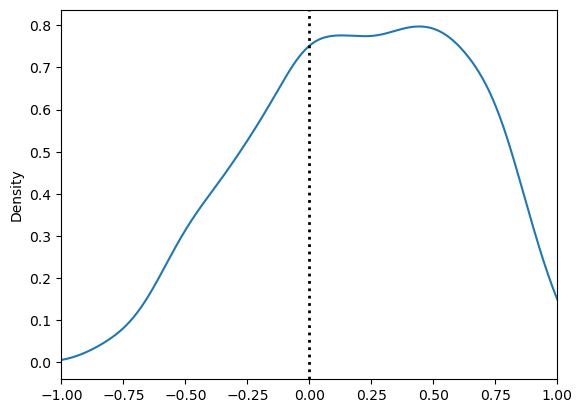

In [29]:
import matplotlib.pyplot as plt
%matplotlib inline
sim_convergences = pd.read_csv("../../simulated_conv_corr_snakeflow.csv")
sim_convergences[sim_convergences['year']==15001]['convergence_correlation'].plot.kde()
plt.axvline(x=0, color='black', linestyle=':', linewidth=2)

plt.xlim(-1, 1)
plt.savefig("snakemake_sim_selfing_95.pdf", bbox_inches='tight', dpi=300)
plt.show()
# sum(sim_convergences['convergence_correlation'] > 1)